<a href="https://colab.research.google.com/github/Francisco-Urgiles/Practicas-IA-UPS/blob/main/practica02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practica 02

---

*Universidad Politécnica Salesiana*
## INTELIGENCIA ARTIFICIAL
**Nombre:** Francisco Urgiles

**Docente:** Rodrigo Tufiño

**Fecha:** 16/10/2026

Celda de verificación: ejecutar antes de iniciar.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
print("✅Todas las librerías cargadas correctamente")

✅Todas las librerías cargadas correctamente


# FASE 1. Anatomía de un Dataset

Dataset de estudiantes. Ejecuta el siguiente bloque. No lo modifiques nada todavía, solo léelo con atención.

In [ ]:
import numpy as np
import pandas as pd

datos = {
    "nombre":        ["Ana",  "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad":          [21,     23,     20,      25,       22,      21],
    "promedio_gpa":  [8.9,    7.4,    9.5,     6.1,      8.2,     7.8],
    "horas_estudio": [18,     10,     22,      6,        15,      12],
    "distancia_km":  [2.5,    15.0,   0.8,     40.2,     5.1,     8.7],
    "carrera":       [
        "Computación","Computación","Redes","Redes","Computación","Redes"],
    "nivel_ingles":  [
        "Básico", "Intermedio","Avanzado","Básico","Avanzado","Intermedio"],
    "beca":          [1,      0,      1,       0,        1,       0],
    "aprobado":      ["Sí",   "No",   "Sí",    "No",     "Sí",    "No"]
}

df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Sí  
1   Intermedio     0       No  
2     Avanzado     1       Sí  
3       Básico     0       No  
4     Avanzado     1       Sí  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)
   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computa

## Actividad 1.1:

**P1. ¿Cuántas instancias (filas) tiene este dataset? ¿Qué representa cada instancia en el mundo real?**

*Respuesta:*
```
- Cuenta con 6 instancias (Filas)
- Representa a los estudiantes
```

**P2. Lista todos los atributos (columnas). Ahora sepáralos en dos grupos: ¿cuáles actuarían como features y cuál sería el label si tu objetivo fuera predecir si un estudiante aprueba o no?**

*Respuesta:*
```
- Atributos totales:
  nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca, aprobado.
- Features (Variables independientes):
  edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca.
- Label (Variable objetivo / Target):
  aprobado.
```

**P3. La columna nombre es un atributo, pero ¿debería ser un feature para un modelo de ML? ¿Por qué sí o por qué no?**

*Respuesta:*

```
- No, la columna 'nombre' no debe usarse como feature. Los nombres son identificadores únicos
```

## Actividad 1.2:

### Clasifica las variables. Completa la siguiente tabla en tu notebook. Para cada columna, indica su tipo según los criterios estudiados en clase:

In [ ]:
clasificacion = {
    "columna": ["edad", "promedio_gpa", "horas_estudio", "distancia_km",
                "carrera", "nivel_ingles", "beca", "aprobado"],
    "cuantitativa_o_cualitativa": ["Cuantitativa", "Cuantitativa", "Cuantitativa", "Cuantitativa",
                                  "Cualitativa", "Cualitativa", "Cualitativa", "Cualitativa"],
    "discreta_o_continua": ["Discreta", "Continua", "Discreta", "Continua",
                            "NA", "NA", "NA", "NA"],
    "nominal_u_ordinal": ["NA", "NA", "NA", "NA",
                          "Nominal", "Ordinal", "Nominal", "Nominal"]
}
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)


         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               Cuantitativa            Discreta   
1   promedio_gpa               Cuantitativa            Continua   
2  horas_estudio               Cuantitativa            Discreta   
3   distancia_km               Cuantitativa            Continua   
4        carrera                Cualitativa                  NA   
5   nivel_ingles                Cualitativa                  NA   
6           beca                Cualitativa                  NA   
7       aprobado                Cualitativa                  NA   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           Nominal  
5           Ordinal  
6           Nominal  
7           Nominal  


**P4. nivel_ingles tiene los valores Básico, Intermedio y Avanzado. ¿Es nominal u ordinal? ¿En qué te basas para decidirlo? ¿Importa esa distinción a la hora de entrenar un modelo?**

*Respuesta:*
```
Es ordinal porque sus categorías (Básico, Intermedio, Avanzado) poseen un orden implícito.
Esta distinción importa porque permite organizarlos d3e forma ordenada.
```

**P5. La columna beca solo contiene 0 y 1. ¿Es cuantitativa discreta o cualitativa nominal? Justifica tu respuesta. Pista: piensa en si tiene sentido calcular la media de esos valores.**

*Respuesta:*

```
Aunque contiene valores numéricos (0 y 1), conceptualmente actúa como una
variable cualitativa nominal (binaria), ya que representan categorías
```

## Actividad 1.3:

### Inspeccionando tipos de datos.

In [ ]:
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


**P6. ¿Coinciden los tipos que detecta pandas (int64, object, float64) con tu clasificación teórica de la actividad 1.2? Señala al menos un caso donde no coincidan y explica por qué pandas puede estar "equivocado" desde la perspectiva conceptual.**

*Respuesta:*
```
No totalmente. Por ejemplo, beca se detecta como int64 debido a sus valores
numéricos, aunque teóricamente es cualitativa categórica.

```

**P7. Observa las estadísticas descriptivas. ¿Qué columna tiene mayor dispersión (std)? ¿Qué problema podría ocasionar esa diferencia de escala si alimentas este dataset directamente a un algoritmo como KNN?**

*Respuesta:*

La columna con mayor desviación estándar es **distancia_km** (aproximadamente 13.8 km), seguida por **horas_estudio** y **promedio_gpa**. En KNN, que calcula distancias entre observaciones, las variables con escalas o dispersión mayores pueden dominar el cálculo. Así, la distancia al campus podría influir más que el promedio académico, aunque no necesariamente sea más importante.

# FASE 2. Escalado con NumPy

En esta fase implementarás los algoritmos desde cero usando solo NumPy. El objetivo es que entiendas exactamente qué hace cada transformación antes de usar una librería que la oculte.

## Actividad 2.1:

### Preparando los datos

In [ ]:
# Extraemos SOLO las columnas numéricas continuas para esta fase
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)

print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape} → {X.shape[0]} instancias, {X.shape[1]} features")

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3) → 6 instancias, 3 features


**P8. ¿Por qué excluimos edad y beca de esta matriz aunque también son numéricas? ¿Tiene sentido escalar la columna beca que solo contiene 0 y 1?**

*Respuesta:*

Se excluye **edad** porque esta actividad se centra en las tres variables continuas indicadas en la guía; además, la edad es una variable cuantitativa discreta. **beca** se excluye porque sus valores 0 y 1 representan categorías (no tiene beca / sí tiene beca), no una magnitud continua. Escalarla normalmente no aporta y puede dificultar la interpretación de la categoría.

## Actividad 2.2:

### Normalización Min-Max

In [ ]:
def min_max_manual(X):
    """
    Normalización Min-Max: transforma cada columna al rango [0, 1]
    Fórmula: x' = (x - min) / (max - min)
    """
    X_min = X.min(axis=0)   # mínimo por columna
    X_max = X.max(axis=0)   # máximo por columna
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print(df_minmax.round(4))

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


**P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0? ¿Y uno de 1.0?**

*Respuesta:*

Cada columna queda entre **0 y 1**, inclusive. El mínimo observado se transforma en 0 y el máximo observado en 1. Un valor 0 indica que la observación tiene el valor mínimo de esa variable dentro del conjunto usado para ajustar la transformación; un valor 1 indica que tiene el máximo.

**P10. Fíjate en la columna distancia_km. Carlos vive a 40.2 km, que es un valor extremo. Ahora imagina que llega un nuevo estudiante que vive a 80 km. Si agregas ese dato y vuelves a normalizar, ¿qué le pasará al valor transformado de todos los demás estudiantes? ¿Es eso un problema? ¿Por qué?**

*Respuesta:*

Al incluir el valor de 80 km, el máximo de **distancia_km** aumentaría de 40.2 a 80. Por eso, los valores Min-Max de los estudiantes existentes disminuirían (quedarían más cerca de 0), aunque sus distancias reales no hayan cambiado. Esto es un problema porque la escala depende de los extremos del conjunto y un valor extremo puede comprimir las diferencias entre las demás observaciones.

## Actividad 2.3:

### Estandarización Z-Score

In [ ]:
def zscore_manual(X):
    """
    Z-Score: transforma cada columna a media=0 y desv.est.=1
    Fórmula: z = (x - media) / desviacion_estandar
    """
    media = X.mean(axis=0)
    std   = X.std(axis=0)        # desviación estándar de la población
    X_z   = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv.Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media    Desv.Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


**P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0? ¿Y uno de 1.0?**

*Respuesta:*

Esta pregunta repite la P9 de Min-Max en la guía; para Z-Score, en cambio, cada columna queda con media aproximadamente 0 y desviación estándar poblacional 1 en los datos usados para calcularla. Un valor negativo significa que está por debajo de la media; uno positivo, por encima. El valor 0 corresponde a la media.

**P12. Carlos tiene horas_estudio = 6. Después del Z-Score, su valor transformado es negativo. ¿Qué significa eso en términos estadísticos? ¿Significa que Carlos estudia "mal"? ¿Qué dice ese valor sobre su posición relativa al grupo?**

*Respuesta:*

El Z-Score de Carlos para horas de estudio es negativo porque sus 6 horas están por debajo de la media del grupo (13.83 horas). No significa que estudie “mal”; solo indica su posición relativa: estudia menos horas que el promedio de estos seis estudiantes.

**P13. Compara los valores de Carlos y Sofía para distancia_km después de Min-Max y después de Z-Score. ¿Cuál de las dos transformaciones te parece más informativa sobre la "rareza" de vivir a 40 km? Argumenta.**

*Respuesta:*

Carlos vive a 40.2 km y Sofía a 5.1 km. Con Min-Max, sus valores son aproximadamente 1.000 y 0.109, respectivamente; con Z-Score, Carlos queda cerca de +2.17 desviaciones estándar y Sofía cerca de −0.50. Z-Score comunica mejor cuántas desviaciones estándar se aleja un valor de la media y, por ello, ayuda a describir lo inusual que es la distancia de Carlos. Ambos métodos siguen siendo sensibles a los extremos.

## Actividad 2.4:

### Comparación visual de las tres columnas

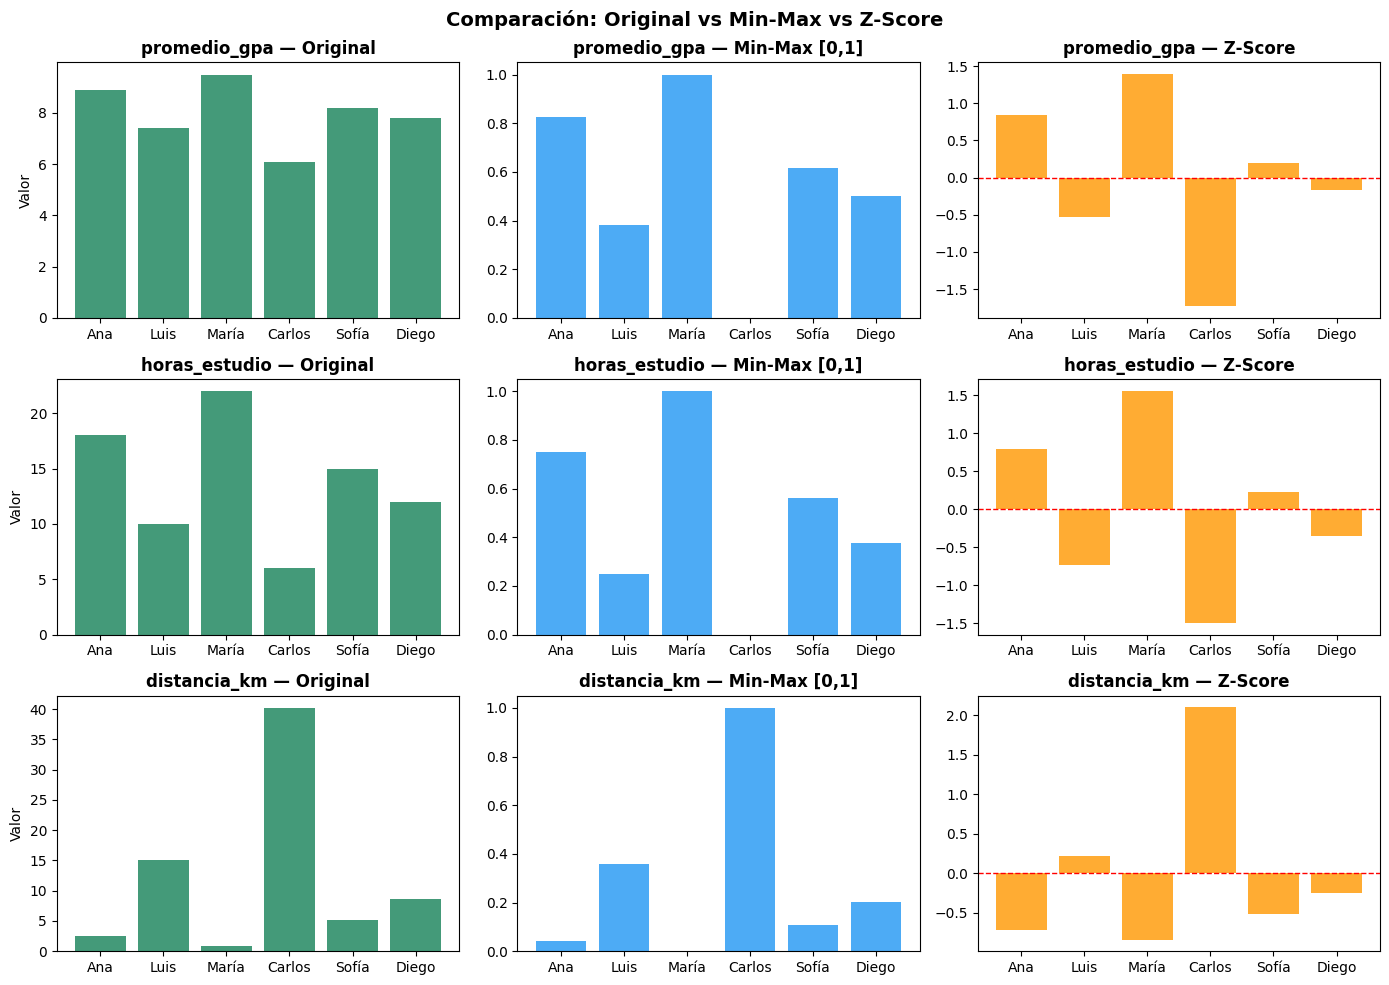

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    # Original
    axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
    axes[i, 0].set_title(f"{col} — Original", fontweight='bold')
    axes[i, 0].set_ylabel("Valor")

    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} — Min-Max [0,1]", fontweight='bold')

    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i, 2].set_title(f"{col} — Z-Score", fontweight='bold')

plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14,
             fontweight='bold')
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()

**P14. Observa la gráfica de distancia_km. Las proporciones relativas entre estudiantes, ¿se mantienen igual en las tres versiones? ¿Qué es lo que realmente cambia entre Original, Min-Max y Z-Score?**

*Respuesta:*

Sí, el orden y las relaciones lineales entre los valores se conservan: dentro de cada columna, quien tenía el valor mayor sigue teniéndolo. Lo que cambia es la escala y el punto de referencia: los datos originales mantienen sus unidades, Min-Max los lleva al intervalo [0, 1] y Z-Score expresa cada dato en desviaciones estándar respecto de la media.

## Actividad 2.5:

### Simulando un outlier extremo

In [ ]:
# Añadimos un estudiante con una distancia extrema
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])  # 120 km

# Aplicamos Min-Max sobre los datos CON outlier
X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)

# Aplicamos Z-Score sobre los datos CON outlier
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
    print(f"{nombres_ext[j]:<10} {X_con_outlier[j,2]:>10.1f} "
          f"{X_mm_con_outlier[j,2]:>10.4f} {X_z_con_outlier[j,2]:>10.4f}")

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


**P15. Observa lo que ocurre con los valores de los otros estudiantes en Min-Max después de agregar el outlier de 120 km. ¿Qué problema genera esto? ¿Por qué Z-Score es más robusto ante este caso? ¿Existe alguna técnica mejor aún?**

*Respuesta:*

El outlier de 120 km hace que el máximo aumente y comprime los valores Min-Max de los otros estudiantes cerca de 0, reduciendo visualmente sus diferencias. Z-Score no es realmente robusto ante outliers: la media y la desviación estándar también se ven afectadas, aunque la interpretación es distinta. Una alternativa más robusta ante valores extremos es **RobustScaler**, que usa la mediana y el rango intercuartílico (IQR).

# FASE 3. Dataset real con Pandas: Palmer Penguins

Ahora trabajarás con un dataset real de Hugging Face. El dataset [Palmer Penguins](https://huggingface.co/datasets/SIH/palmer-penguins), creado originalmente como paquete de R, fue diseñado para reemplazar al famoso Iris dataset en tareas de exploración y visualización de datos.

In [ ]:
import pandas as pd

# Cargamos el dataset directamente desde Hugging Face
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones: (344, 

## Actividad 3.1:

### Exploración inicial obligatoria

In [ ]:
print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

print("\n=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===")
for col in df_penguins.select_dtypes(include='object').columns:
    print(f"{col}: {df_penguins[col].unique()}")


=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

=== ESTADÍSTICAS DESCRIPTIVAS ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
count      342.000000     342.000000         342.000000   342.000000   
mean        43.921930      17.151170         200.915205  4201.754386   
std          5.459584       1.974793          14.061714   801.954536   
min         32.100000      13.100000         172.000000  2700.000000   
25%         39.225000      15.600000         190.000000  3550.000000   
50%         44.450000      17.30000

**P16. Identifica para este dataset: ¿cuántas instancias tiene? ¿Cuáles son las features numéricas? ¿Cuál sería el label más lógico para una tarea de clasificación?**

*Respuesta:*

El dataset original tiene **344 instancias**. Las features numéricas son **bill_length_mm`, `bill_depth_mm**, **flipper_length_mm** y **body_mass_g** (también hay una columna numérica de índice/identificador si aparece en el archivo, pero no es una medida biológica que convenga usar como feature). Para una clasificación, el label más lógico es **species**, porque identifica la especie del pingüino.

**P17. ¿Hay valores nulos? ¿En qué columnas? ¿Por qué es importante tratar los valores nulos antes de aplicar escalado? ¿Qué pasaría si escalas con NaN presentes?**

*Respuesta:*

Sí, hay valores nulos en algunas columnas, como **bill_length_mm**, **bill_depth_mm**, **flipper_length_mm**, **body_mass_g** y **sex** (la cantidad exacta se muestra con **isnull().sum()**). Deben tratarse antes de escalar porque los NaN pueden propagarse a los resultados o provocar errores según el transformador. En esta práctica se eliminan las filas que contienen valores nulos.

## Actividad 3.2:

### Clasificación de variables del dataset

**P18. Para cada columna de df_penguins, clasifica su tipo completo. Presta especial atención a sex e island. ¿Son las dos nominales? ¿Cambiaría la respuesta si ordenamos las islas por temperatura promedio del océano?**

*Respuesta:*

La clasificación depende del significado de cada variable:

- **species**: cualitativa nominal; categorías sin orden.
- **island**: cualitativa nominal; los nombres de las islas no tienen un orden intrínseco.
- **bill_length_mm**, **bill_depth_mm**, **flipper_length_mm**, **body_mass_g**: cuantitativas continuas.
- **sex**: cualitativa nominal, pues sus categorías no tienen un orden.
- **year**: cuantitativa discreta si representa el año numérico de observación; también puede tratarse como variable temporal.

Ordenar las islas por temperatura promedio no convierte automáticamente a **island** en ordinal: eso crearía un orden derivado de otra característica y debería justificarse explícitamente para una pregunta concreta.

## Actividad 3.3:

### Preprocesamiento y escalado

In [ ]:
# Paso 1: Eliminar filas con valores nulos
df_clean = df_penguins.dropna()
print(f"Filas originales: {len(df_penguins)} → Filas limpias: {len(df_clean)}")

# Paso 2: Seleccionar features numéricas
features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values

print("\nEstadísticas ANTES del escalado:")
print(pd.DataFrame(X_penguins, columns=features_num).describe().round(2))

Filas originales: 344 → Filas limpias: 333

Estadísticas ANTES del escalado:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


**P19. Mira las escalas de body_mass_g (en gramos, ~3500–6000) vs bill_depth_mm (en mm, ~13–21). Si entrenas un modelo con estos datos sin escalar, ¿cuál variable tendrá más peso en el cálculo de distancia? ¿Es eso justo biológicamente?**

*Respuesta:*

**body_mass_g** tiene valores del orden de miles, mientras que **bill_depth_mm** está aproximadamente entre 13 y 21. En un cálculo de distancia sin escalado, la masa corporal puede dominar por su magnitud numérica. Eso no es necesariamente justo biológicamente: depende de las unidades elegidas y no de la relevancia real de cada característica. El escalado permite que las variables contribuyan en escalas comparables.

## Actividad 3.4:

### Análisis de distribuciones

In [ ]:
# Paso 3: Aplicar Min-Max
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

# Paso 4: Aplicar Z-Score
zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

# Paso 5: Comparar estadísticas
print("\n--- Min-Max ---")
print(pd.DataFrame(X_mm, columns=features_num).describe().round(4))

print("\n--- Z-Score ---")
print(pd.DataFrame(X_zs, columns=features_num).describe().round(4))


--- Min-Max ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

--- Z-Score ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673            -2.0699      -1.8744


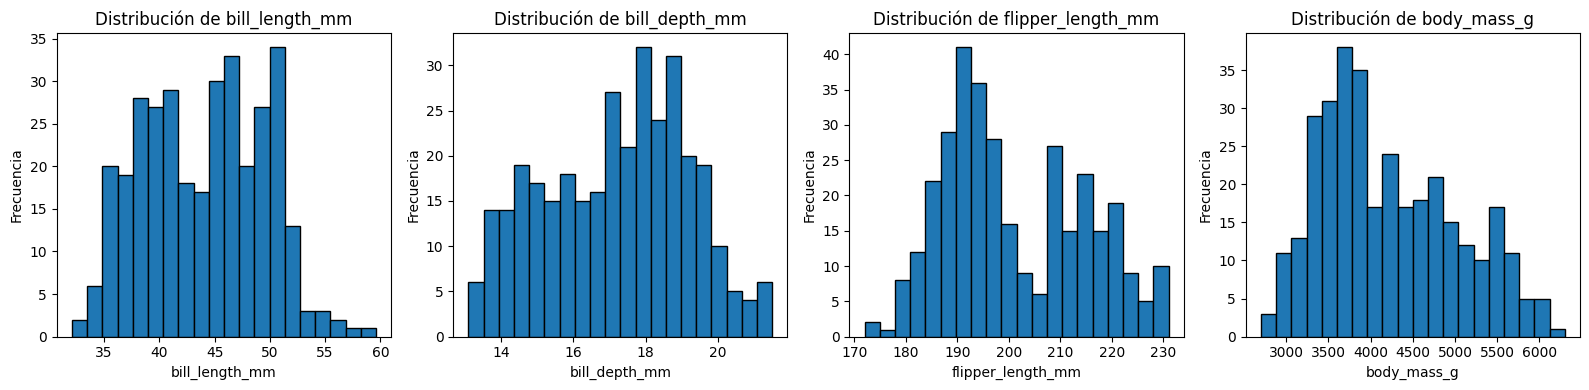

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, features_num):
    ax.hist(df_clean[col], bins=20, edgecolor="black")
    ax.set_title(f"Distribución de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()


**P20. ¿El escalado cambia la forma de la distribución (histograma) o solo la escala de los ejes? ¿Por qué importa esa respuesta cuando evaluamos normalidad de los datos?**

*Respuesta:*

El escalado Min-Max y Z-Score es una transformación lineal de cada variable; por sí solo no elimina la asimetría ni convierte una distribución no normal en normal. En general, cambia los valores del eje horizontal, pero conserva la forma de la distribución. Por eso, para evaluar normalidad hay que observar la forma (por ejemplo, con histogramas o gráficos Q-Q), no solo la escala o la media y desviación estándar.

**P21. Observa la distribución de body_mass_g. ¿Se parece a una campana de Gauss (distribución normal) o tiene alguna asimetría? ¿Afecta eso a la elección entre Min-Max y Z-Score?**

*Respuesta:*

La distribución de **body_mass_g** no tiene por qué formar una campana perfecta: al combinar varias especies y sexos, puede mostrar grupos o cierta asimetría. Min-Max y Z-Score no corrigen esa forma ni la asimetría; la elección depende del objetivo y de la presencia de valores extremos. Min-Max es útil si se necesita un rango fijo, Z-Score centra respecto de media y desviación estándar, y RobustScaler suele convenir más cuando hay outliers.

# FASE 4: HuggingFace + sklearn

En la fase anterior implementaste Min-Max y Z-Score desde cero con NumPy. Ahora vas a reproducir exactamente los mismos resultados usando sklearn, y añadirás un tercer método que no puedes implementar tan fácilmente a mano: el Robust Scaler. El dataset sigue siendo Palmer Penguins, que ya conoces.

## Actividad 4.1:

### Retornando al dataset limpio

Asegúrate de tener el DataFrame **df_clean** y las columnas **features_num** de la Fase 3. Si reiniciaste el kernel, ejecuta esto:

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()

features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]

X = df_clean[features_num].values

print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")
print(f"\nEstadísticas originales:")
print(pd.DataFrame(X, columns=features_num).describe().round(2))

Dataset listo: 333 instancias, 4 features

Estadísticas originales:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


**P22. Antes de continuar: ¿cuál de las cuatro features tiene mayor rango (max − min)? ¿Cuál tiene menor rango? Calcula ambos valores con código y anótalos, los vas a necesitar para comparar después.**

In [ ]:
rangos = df_clean[features_num].max() - df_clean[features_num].min()
print("Rango (máximo - mínimo) por feature:")
print(rangos.sort_values(ascending=False).to_string())
print(f"Mayor rango: {rangos.idxmax()} = {rangos.max():.2f}")
print(f"Menor rango: {rangos.idxmin()} = {rangos.min():.2f}")


Rango (máximo - mínimo) por feature:
body_mass_g          3600.0
flipper_length_mm      59.0
bill_length_mm         27.5
bill_depth_mm           8.4
Mayor rango: body_mass_g = 3600.00
Menor rango: bill_depth_mm = 8.40


*Respuesta:*

Con las filas limpias y las cuatro features indicadas, el rango se calcula como máximo menos mínimo por columna. El código de la celda anterior a esta respuesta imprime ambos valores y permite identificar la feature con mayor y menor rango; el rango más grande corresponde a **body_mass_g** por estar medido en gramos, mientras que el menor suele corresponder a **bill_depth_mm**.

## Actividad 4.2:

### División train/test. Antes de escalar, el dataset debe dividirse. Este orden no es opcional.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X,
    test_size=0.2,       # 80% entrenamiento, 20% prueba
    random_state=42      # fija la aleatoriedad para reproducibilidad
)

print(f"Train: {X_train.shape} → {X_train.shape[0]} pingüinos")
print(f"Test:  {X_test.shape}  → {X_test.shape[0]} pingüinos")

Train: (266, 4) → 266 pingüinos
Test:  (67, 4)  → 67 pingüinos


**P23. ¿Por qué se divide el dataset antes de aplicar el escalado y no después? Piensa en qué información usaría el scaler si lo aplicaras primero sobre todo el dataset. ¿Qué datos del test estarías "filtrando" al proceso de entrenamiento? Esto se llama data leakage; explícalo con tus propias palabras.**

*Respuesta:*

Se divide antes para evitar **data leakage**. Si el escalador se ajusta usando todo el dataset, los mínimos, máximos, medias o desviaciones estándar incorporan información del conjunto de prueba. Aunque no se usen sus etiquetas, el proceso de entrenamiento ya habría aprovechado información del test. Por eso se aprende el escalado solo con **X_train** y luego se aplica sin recalcular parámetros a **X_test**.

## Actividad 4.3:

### Aplicando los tres escaladores. El patrón de uso es siempre el mismo:

- **fit_transform(X_train)** → aprende los parámetros del train y lo transforma
- **transform(X_test)** → aplica los mismos parámetros aprendidos al test, sin recalcularlos

In [ ]:
# Instanciar los tres escaladores
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

# Aplicar a train: fit + transform
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

# Aplicar a test: solo transform (NO fit)
X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)

print("Parámetros aprendidos por MinMaxScaler (sobre train):")
print(f"  Mínimos:  {mm_scaler.data_min_.round(2)}")
print(f"  Máximos:  {mm_scaler.data_max_.round(2)}")

print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f"  Medias:   {zs_scaler.mean_.round(2)}")
print(f"  Std:      {zs_scaler.scale_.round(2)}")

print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f"  Medianas: {rb_scaler.center_.round(2)}")
print(f"  IQR:      {rb_scaler.scale_.round(2)}")

Parámetros aprendidos por MinMaxScaler (sobre train):
  Mínimos:  [  32.1   13.1  172.  2700. ]
  Máximos:  [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
  Medias:   [  44.08   17.07  201.41 4232.61]
  Std:      [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
  Medianas: [  44.9   17.2  197.  4100. ]
  IQR:      [   8.9    3.2   24.  1200. ]


**P22. Compara los parámetros que aprendió MinMaxScaler (mínimos y máximos) con los que calculaste manualmente en la Fase 2 con NumPy. ¿Son exactamente iguales o hay alguna diferencia pequeña? ¿A qué se debe si la hay?**

*Respuesta:*

Los mínimos y máximos de **MinMaxScaler** corresponden al conjunto **X_train** de Palmer Penguins, mientras que la Fase 2 usó un dataset pequeño de estudiantes. Por tanto, no deben coincidir numéricamente porque son datasets distintos. Para una comparación válida, se calculan manualmente los mínimos y máximos de **X_train** y se comparan con **mm_scaler.data_min_** y **mm_scaler.data_max_**; deberían coincidir salvo diferencias de precisión numérica.

**P23. El RobustScaler aprende la mediana y el IQR de cada columna, no la media ni el std. Calcula manualmente la mediana y el IQR de body_mass_g en el train con NumPy y verifica que coincidan con rb_scaler.center_[3] y rb_scaler.scale_[3].**

In [ ]:
# Verificación manual de mediana e IQR para body_mass_g (columna índice 3)
masa_train = X_train[:, 3]
mediana_manual = np.median(masa_train)
q1, q3 = np.percentile(masa_train, [25, 75])
iqr_manual = q3 - q1

print(f"Mediana manual de body_mass_g: {mediana_manual:.4f}")
print(f"Mediana RobustScaler:          {rb_scaler.center_[3]:.4f}")
print(f"IQR manual de body_mass_g:     {iqr_manual:.4f}")
print(f"IQR RobustScaler:              {rb_scaler.scale_[3]:.4f}")
print("Medianas coinciden:", np.isclose(mediana_manual, rb_scaler.center_[3]))
print("IQR coincide:", np.isclose(iqr_manual, rb_scaler.scale_[3]))


Mediana manual de body_mass_g: 4100.0000
Mediana RobustScaler:          4100.0000
IQR manual de body_mass_g:     1200.0000
IQR RobustScaler:              1200.0000
Medianas coinciden: True
IQR coincide: True


*Respuesta:*

La mediana manual se obtiene con **np.median(X_train[:, 3])** y el IQR con el percentil 75 menos el percentil 25. Estos resultados deben coincidir con **rb_scaler.center_[3]** y **rb_scaler.scale_[3]**, respectivamente, porque RobustScaler se ajustó usando **X_train**. El código de la celda anterior verifica la igualdad.

# CONCLUSIONES

**Cada estudiante debe agregar al menos una conclusión propia derivada de sus observaciones específicas.**

*Respuesta:*

1. El escalado es importante en algoritmos basados en distancias porque evita que una variable domine únicamente por sus unidades o magnitud.
2. Min-Max es útil cuando se necesita un rango fijo, pero depende de los valores mínimo y máximo y es sensible a outliers.
3. Z-Score expresa los datos en relación con la media y desviación estándar, pero tampoco es robusto ante valores extremos.
4. RobustScaler usa mediana e IQR, por lo que suele conservar mejor la escala central cuando existen outliers.
5. Es fundamental dividir train/test antes de ajustar cualquier escalador para evitar data leakage.